# Purging Every Combination

The protected training set for split $s$ is:

$$
T_s^{\mathrm{safe}}
=\left\{i\notin S_s:
I_i\cap\left(\bigcup_{j\in S_s}I_j\right)=\varnothing,
\ i\notin E_s\right\}.
$$

Here, $S_s$ is the test set, $I_i$ is the information interval of observation $i$, $E_s$ is the embargoed region, and $T_s^{\mathrm{safe}}$ is the training set that remains after removing shared label time and the declared buffer.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("17_combinatorial_purged_cross_validation");
using CSV, TOML, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
using RiskLabAI.Validation: KFoldCV,PurgedKFoldCV,WalkForwardCV,cv_split,backtest_predictions,filtered_training_indices_with_embargo
prefix = "construction"
raw = load_binance()
raw.interval = floor.(raw.time,Minute(15))

function compensated_sum(values)
    total,correction = 0.,0.
    for value in values
        adjusted = value-correction
        updated = total+adjusted
        correction = updated-total-adjusted
        total = updated
    end
    return total
end

bars = combine(groupby(raw,:interval;sort=true),:close=>last=>:Close,:volume=>compensated_sum=>:Volume,:quote_volume=>compensated_sum=>Symbol("Quote volume"),:trades=>compensated_sum=>:Trades)
levels = log.(bars.Close)
returns = vcat(NaN,diff(levels))
positions = collect(18:nrow(bars)-8)
feature_names = ["Previous return","One-hour return","Past volatility","Log volume change","Log quote-volume change","Log trade-count change"]
public_x = hcat(returns[positions.-1],levels[positions.-1].-levels[positions.-5],[std(returns[index-16:index-1]) for index in positions],diff(log1p.(bars.Volume))[positions.-2],diff(log1p.(bars[!,"Quote volume"]))[positions.-2],diff(log1p.(bars.Trades))[positions.-2])
dates,event_times = bars.interval[positions],bars.interval[positions.+8]
forward_returns = levels[positions.+8].-levels[positions]
public_y = Int.(forward_returns.>0)
count_observations = length(public_y)
feature_frame = DataFrame(position=collect(1:count_observations),bar_position=positions,date=dates,end_time=event_times,forward_return=forward_returns,target=public_y)
for (column,name) in enumerate(feature_names)
    feature_frame[!,name] = public_x[:,column]
end
save_data(feature_frame,paths,prefix*"_features")
save_data(bars,paths,prefix*"_bars")
violet = "#C084FC"
split_colors = [palette.grid,palette.cyan,palette.rose,palette.amber,violet]
format_time(value) = Dates.format(value,dateformat"yyyy-mm-dd HH:MM:SS")

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter15-"*replace(name,"_"=>"-"))
end

function save_splits(key,splits)
    evidence = DataFrame(fold=Int[],role=String[],order=Int[],position=Int[])
    for (fold,(train,test)) in enumerate(splits), (role,indices) in [("train",train),("test",test)]
        append!(evidence,DataFrame(fold=fill(fold,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
    end
    save_data(evidence,paths,key*"_splits")
    return nothing
end

function overlap_count(train,test)
    allowed = Set(filtered_training_indices_with_embargo(dates,event_times,test;embargo=0.,continuous=false))
    return count(index->index∉allowed,train)
end

function split_matrix(splits)
    result = zeros(Int,length(splits),count_observations)
    for (fold,(train,test)) in enumerate(splits)
        result[fold,train] .= 1
        result[fold,test] .= 2
    end
    return result
end

function split_legend!(figure;full=false)
    labels = ["Excluded","Train","Test","Overlap removed","Embargo removed"]
    for index in 1:(full ? 5 : 3)
        plot!(figure,[NaN],[NaN];color=split_colors[index],marker=:rect,linewidth=3,label=labels[index])
    end
    plot!(figure;legend=:outerright,colorbar=false)
    return figure
end

using Combinatorics: combinations
using RiskLabAI.Validation: CombinatorialPurgedCV,BaggedCombinatorialPurgedCV,AdaptiveCombinatorialPurgedCV,backtest_paths,get_n_splits
@assert count_observations==2951 && size(public_x)==(2951,6)
external_feature = public_x[:,3]
state_colors = [palette.grid,palette.cyan,palette.rose,palette.amber]
path_colors = [palette.background,palette.cyan,palette.amber,palette.green,palette.rose,violet]

function categorical_legend!(figure,colors,labels)
    for (color,label) in zip(colors,labels)
        plot!(figure,[NaN],[NaN];color,marker=:rect,linewidth=3,label)
    end
    plot!(figure;colorbar=false,legend=:outerright)
    return figure
end

function save_matrix(values,name)
    frame = DataFrame(values,:auto)
    insertcols!(frame,1,:row=>collect(1:size(values,1)))
    save_data(frame,paths,name)
    return nothing
end

function path_scores(method,predictions)
    rows = NamedTuple[]
    for number in sort(collect(keys(predictions)))
        values = predictions[number]
        push!(rows,(method=method,path=number,predictions=length(values),correct=sum(values.==public_y),accuracy=mean(values.==public_y),positive_share=mean(values.==1)))
    end
    result = DataFrame(rows)
    rename!(result,["Method","Path","Predictions","Correct predictions","Accuracy","Positive prediction share"])
    return result
end

function fit_paths(validator,name;sample_indices=nothing,feature_indices=nothing,estimator_seeds=nothing)
    members = validator isa BaggedCombinatorialPurgedCV ? validator.n_estimators : 1
    records,models = NamedTuple[],BookEstimators.LogisticModel[]
    data_positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(public_x)))
    @assert length(data_positions)==count_observations
    fit_callback = function(seed,x,y,weights)
        fit_number = length(records)+1
        split,member = cld(fit_number,members),mod1(fit_number,members)
        model = BookLogisticLBFGS.fit_logistic(x,y;sample_weight=weights,C=1.,standardize=true,class_weight=nothing,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,model)
        fields = Dict{Symbol,Any}(:split=>split,:member=>member,:seed=>seed,:training_observations=>length(y),:weight_sum=>sum(weights),:positive_weights=>count(>(0),weights),:intercept=>model.intercept,:objective=>model.objective,:gradient_norm=>model.gradient_norm,:iterations=>model.iterations,:converged=>model.converged)
        for index in 1:6
            fields[Symbol("b",index)] = model.coefficients[index]
            fields[Symbol("center",index)] = model.scaler.center[index]
            fields[Symbol("scale",index)] = model.scaler.scale[index]
        end
        keys_order = [:split,:member,:seed,:training_observations,:weight_sum,:positive_weights,:intercept,:objective,:gradient_norm,:iterations,:converged]
        append!(keys_order,[Symbol(prefix,index) for prefix in ["b","center","scale"] for index in 1:6])
        push!(records,NamedTuple{Tuple(keys_order)}(Tuple(fields[key] for key in keys_order)))
        save_data(DataFrame(position=[data_positions[Tuple(row)] for row in eachrow(x)],weight=weights),paths,name*"_fit_"*string(fit_number)*"_weights")
        return model
    end
    predictions = if members==1
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=identity,fit_estimator=fit_callback,predict=BookEstimators.predict)
    else
        backtest_predictions(validator,15,public_x,public_y;clone_estimator=(_,seed)->seed,fit_estimator=fit_callback,predict=BookEstimators.predict,predict_proba=BookEstimators.predict_proba,estimator_classes=model->model.classes,fit_sample_weights=true,sample_indices,feature_indices,estimator_seeds)
    end
    save_data(DataFrame(records),paths,name*"_fits")
    evidence = DataFrame(position=collect(1:count_observations),date=dates,actual=public_y)
    for number in sort(collect(keys(predictions)))
        evidence[!,"path_"*string(number)] = predictions[number]
    end
    save_data(evidence,paths,name*"_predictions")
    save_splits(name,cv_split(validator))
    return predictions,models
end


fit_paths (generic function with 1 method)

## Protected Split Composition

Row,Split,Test groups,Original training observations,Test observations,Removed observations,Final training observations,Overlapping retained labels
,Int64,String,Int64,Int64,Int64,Int64,Int64
1,1,1 and 2,1967,984,37,1930,0
2,2,1 and 3,1967,984,82,1885,0
3,3,1 and 4,1967,984,82,1885,0
4,4,1 and 5,1967,984,82,1885,0
5,5,1 and 6,1968,983,45,1923,0
6,6,2 and 3,1967,984,45,1922,0
7,7,2 and 4,1967,984,90,1877,0
8,8,2 and 5,1967,984,90,1877,0
9,9,2 and 6,1968,983,53,1915,0


Row,Quantity,Value
,String,Float64
1,Combinatorial splits,15.0
2,Mean original training observations,1967.33
3,Mean test observations,983.667
4,Mean removed observations,60.0
5,Smallest final training set,1877.0
6,Largest final training set,1960.0
7,Retained overlapping labels,0.0


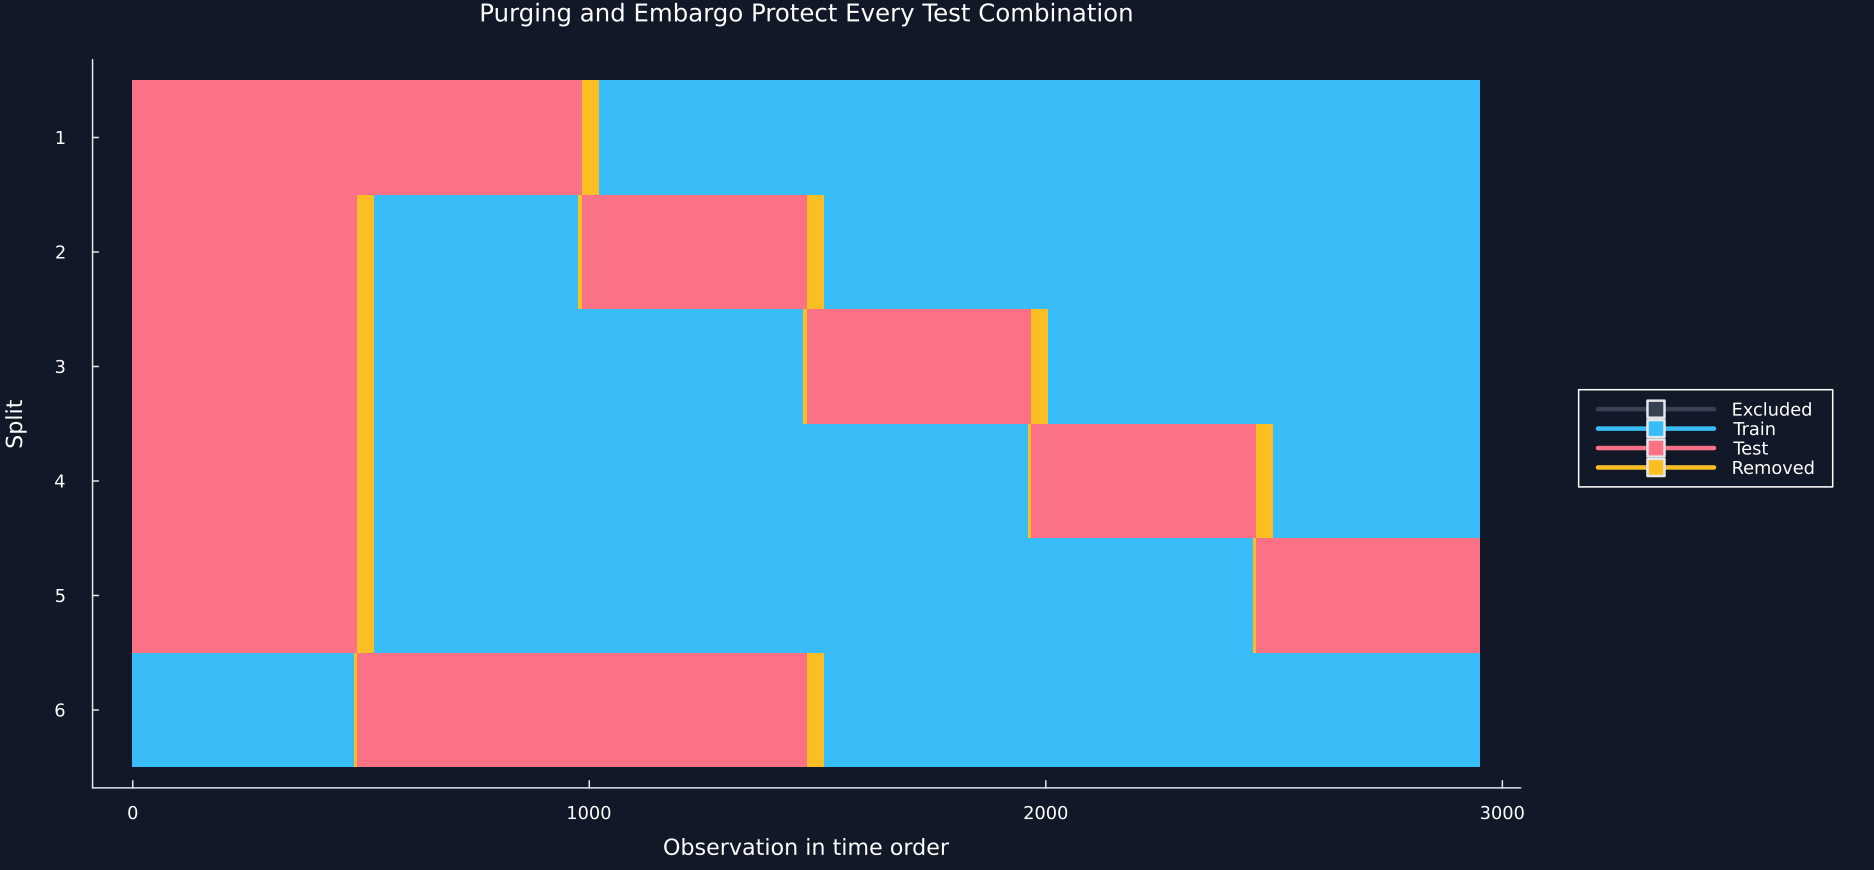

In [2]:
n_groups,n_test_groups,embargo_fraction = 6,2,.01
validator = CombinatorialPurgedCV(n_groups,n_test_groups,dates,event_times;embargo=embargo_fraction)
combinations_list = collect(combinations(1:n_groups,n_test_groups))
split_segments = RiskLabAI.Validation._validation_segments(validator)
protected_splits = cv_split(validator)
split_records = NamedTuple[]
display_matrix = zeros(Int,6,count_observations)
for (split,((train,test),groups)) in enumerate(zip(protected_splits,combinations_list))
    original_train = setdiff(1:count_observations,test)
    removed = setdiff(original_train,train)
    push!(split_records,(split=split,groups=join(groups," and "),original=length(original_train),test=length(test),removed=length(removed),final=length(train),overlap=overlap_count(train,test)))
    if split<=6
        display_matrix[split,train] .= 1
        display_matrix[split,test] .= 2
        display_matrix[split,removed] .= 3
    end
end
split_composition = DataFrame(split_records)
rename!(split_composition,["Split","Test groups","Original training observations","Test observations","Removed observations","Final training observations","Overlapping retained labels"])
table(split_composition,"split_composition","Training, testing, and removed observations across all fifteen combinatorial splits.")
purge_summary = DataFrame("Quantity"=>["Combinatorial splits","Mean original training observations","Mean test observations","Mean removed observations","Smallest final training set","Largest final training set","Retained overlapping labels"],"Value"=>[nrow(split_composition),mean(split_composition[!,"Original training observations"]),mean(split_composition[!,"Test observations"]),mean(split_composition[!,"Removed observations"]),minimum(split_composition[!,"Final training observations"]),maximum(split_composition[!,"Final training observations"]),sum(split_composition[!,"Overlapping retained labels"])])
table(purge_summary,"purge_summary","Summary of protected training sets for the public-data combinatorial design.")
save_splits("construction",protected_splits)
save_matrix(display_matrix,"purge_combination_geometry")
figure = heatmap(1:count_observations,1:6,display_matrix;color=cgrad(state_colors,categorical=true),clims=(-.5,3.5),colorbar=false,yflip=true,yticks=1:6,xlabel="Observation in time order",ylabel="Split",title="Purging and Embargo Protect Every Test Combination",size=(1250,580),grid=false)
categorical_legend!(figure,state_colors,["Excluded","Train","Test","Removed"])
save_figure(figure,paths,"purge_combination_geometry")


The test-cell incidence matrix records the design before paths are assembled:

$$
A_{g,s}=\mathbf 1\{g\in C_s\},
\qquad
\sum_{s=1}^{S}A_{g,s}=\varphi(N,k).
$$

Here, $A_{g,s}$ equals one when time group $g$ is tested in split $s$, $C_s$ is the set of tested groups in that split, $S$ is the total number of splits, and $\varphi(N,k)$ is the number of complete paths.

## Joining Split Segments

Row,Path,Segment,Time group,Source split,Training observations,Test observations,Test begins,Test ends
,Int64,Int64,Int64,Int64,Int64,Int64,String,String
1,1,1,1,1,1930,492,2021-01-01 04:15:00,2021-01-06 07:00:00
2,1,2,2,1,1930,492,2021-01-06 07:15:00,2021-01-11 10:00:00
3,1,3,3,2,1885,492,2021-01-11 10:15:00,2021-01-16 13:00:00
4,1,4,4,3,1885,492,2021-01-16 13:15:00,2021-01-21 16:00:00
5,1,5,5,4,1885,492,2021-01-21 16:15:00,2021-01-26 19:00:00
6,1,6,6,5,1923,491,2021-01-26 19:15:00,2021-01-31 21:45:00
7,2,1,1,2,1885,492,2021-01-01 04:15:00,2021-01-06 07:00:00
8,2,2,2,6,1922,492,2021-01-06 07:15:00,2021-01-11 10:00:00
9,2,3,3,6,1922,492,2021-01-11 10:15:00,2021-01-16 13:00:00


Row,Path,Segments,Test observations,Mean training observations,Smallest training set,Largest training set
,Int64,Int64,Int64,Float64,Int64,Int64
1,1,6,2951,1906.33,1885,1930
2,2,6,2951,1899.67,1877,1922
3,3,6,2951,1899.67,1877,1922
4,4,6,2951,1899.67,1877,1922
5,5,6,2951,1931.33,1915,1960


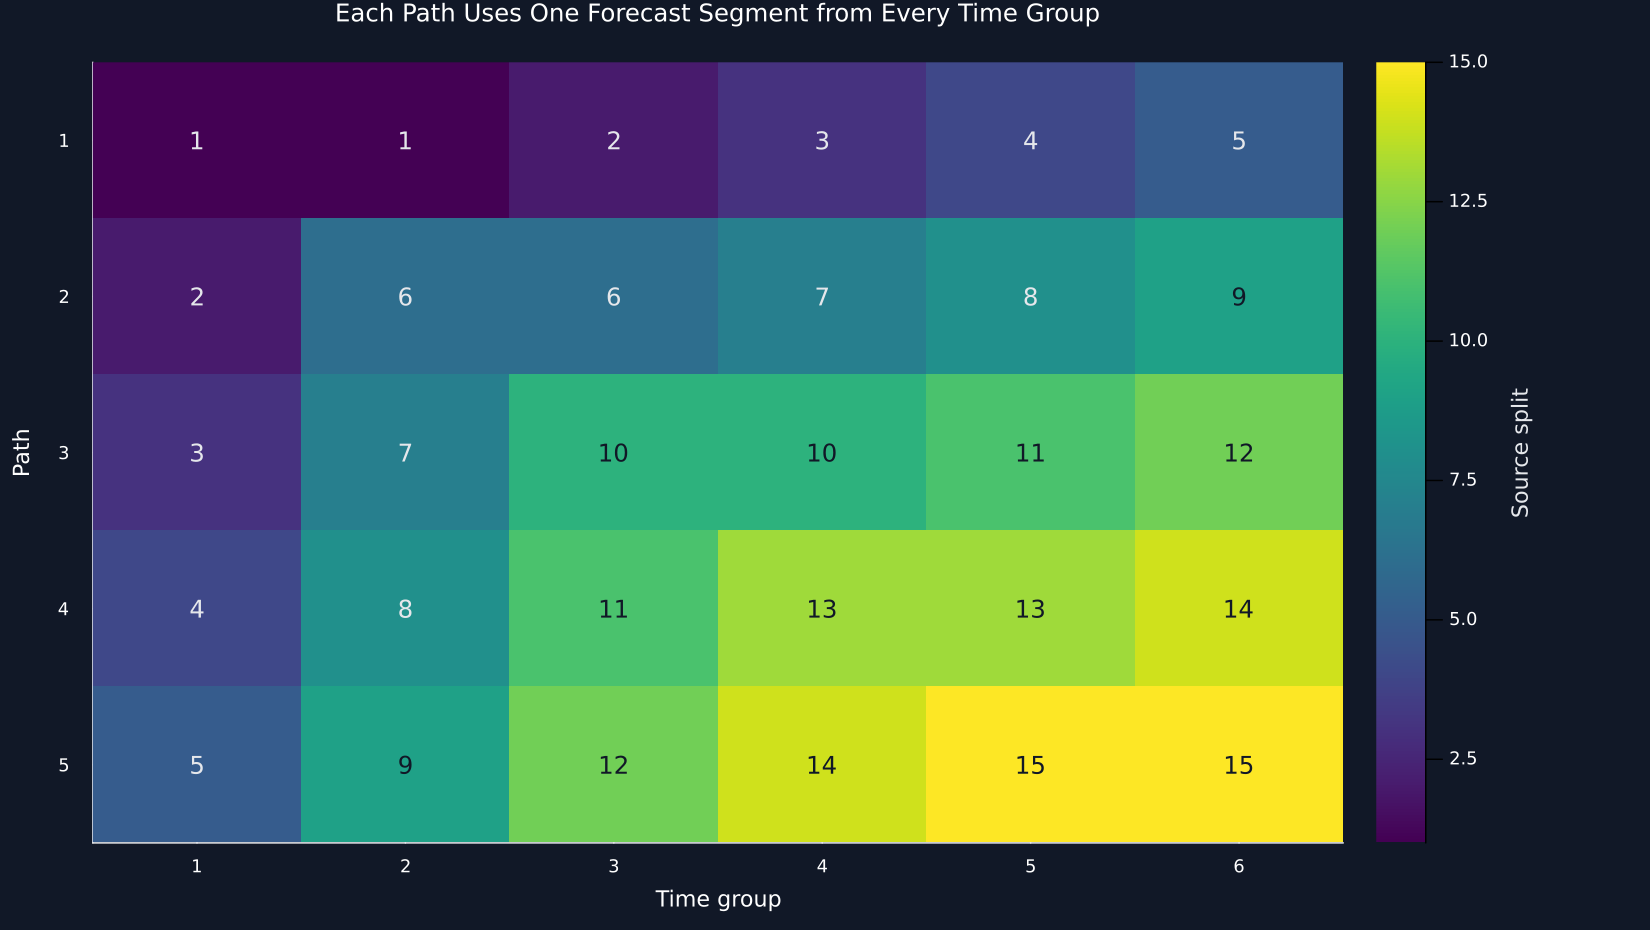

In [3]:
path_sets = backtest_paths(validator)
location_map = RiskLabAI.Validation._path_locations(n_groups,combinations_list)
segment_records = NamedTuple[]
path_split_grid = zeros(Int,length(path_sets),n_groups)
path_rows = DataFrame(path=Int[],segment=Int[],role=String[],order=Int[],position=Int[])
for path in sort(collect(keys(path_sets)))
    for (segment,((train,test),(group,split))) in enumerate(zip(path_sets[path],sort(location_map[path];by=first)))
        path_split_grid[path,group] = split
        push!(segment_records,(path=path,segment=segment,group=group,split=split,training=length(train),test=length(test),begins=format_time(dates[first(test)]),ends=format_time(dates[last(test)])))
        for (role,indices) in [("train",train),("test",test)]
            append!(path_rows,DataFrame(path=fill(path,length(indices)),segment=fill(segment,length(indices)),role=fill(role,length(indices)),order=collect(eachindex(indices)),position=indices))
        end
    end
end
save_data(path_rows,paths,"construction_paths")
path_segment_summary = DataFrame(segment_records)
rename!(path_segment_summary,["Path","Segment","Time group","Source split","Training observations","Test observations","Test begins","Test ends"])
table(path_segment_summary,"path_segment_summary","Source split and sample sizes for every public-data path segment.")
path_coverage_summary = combine(groupby(path_segment_summary,:Path;sort=true),nrow=>"Segments","Test observations"=>sum=>"Test observations","Training observations"=>mean=>"Mean training observations","Training observations"=>minimum=>"Smallest training set","Training observations"=>maximum=>"Largest training set")
table(path_coverage_summary,"path_coverage_summary","Coverage and training sizes for the five complete backtest paths.")
save_matrix(path_split_grid,"path_segment_map")
figure = heatmap(1:6,1:5,path_split_grid;color=:viridis,clims=(1,15),yflip=true,xticks=1:6,yticks=1:5,xlabel="Time group",ylabel="Path",colorbar_title="Source split",title="Each Path Uses One Forecast Segment from Every Time Group",size=(1100,620),grid=false,right_margin=18Plots.mm)
for row in 1:5, column in 1:6
    ink = path_split_grid[row,column]>=9 ? palette.background : palette.text
    annotate!(figure,column,row,text(string(path_split_grid[row,column]),11,ink))
end
save_figure(figure,paths,"path_segment_map")


A complete path score averages one held-out loss for every observation:

$$
R_p=\frac{1}{T}\sum_{i=1}^{T}\ell\!\left(y_i,\widehat f_{s(p,i)}(x_i)\right).
$$

Here, $p$ identifies a backtest path, $T$ is the number of observations, $s(p,i)$ is the split that supplies observation $i$ on path $p$, $\widehat f_s$ is fitted on the protected training set of split $s$, and $\ell$ is the chosen loss.

## Embargo Sensitivity

In [4]:
embargo_records = NamedTuple[]
for (index,embargo) in enumerate([0.,.005,.01,.02])
    current = cv_split(CombinatorialPurgedCV(n_groups,n_test_groups,dates,event_times;embargo))
    removals = [count_observations-length(test)-length(train) for (train,test) in current]
    final_sizes = [length(train) for (train,_) in current]
    push!(embargo_records,(embargo=embargo,removed=mean(removals),maximum_removed=maximum(removals),mean_final=mean(final_sizes),minimum_final=minimum(final_sizes)))
    save_splits("embargo_"*string(index),current)
end
embargo_sensitivity = DataFrame(embargo_records)
rename!(embargo_sensitivity,["Embargo fraction","Mean removed observations","Largest removed observations","Mean final training observations","Smallest final training set"])
table(embargo_sensitivity,"embargo_sensitivity","Sensitivity of combinatorial training sizes to the embargo fraction.")


Row,Embargo fraction,Mean removed observations,Largest removed observations,Mean final training observations,Smallest final training set
,Float64,Float64,Int64,Float64,Int64
1,0.0,21.3333,32,1946.0,1935
2,0.005,40.0,60,1927.33,1907
3,0.01,60.0,90,1907.33,1877
4,0.02,100.0,150,1867.33,1817


## Tests

In [5]:
@assert length(protected_splits)==15
@assert size(split_composition)==(15,7)
@assert all(==(0),split_composition[!,"Overlapping retained labels"])
@assert all(>(0),split_composition[!,"Removed observations"])
@assert all(split_composition[!,"Final training observations"].<split_composition[!,"Original training observations"])
@assert size(purge_summary)==(7,2)
@assert length(path_sets)==5
@assert all(length(segments)==6 for segments in values(path_sets))
@assert size(path_segment_summary)==(30,8)
@assert size(path_coverage_summary)==(5,6)
@assert all(==(count_observations),path_coverage_summary[!,"Test observations"])
@assert all(>(0),path_split_grid)
@assert size(embargo_sensitivity)==(4,5)
@assert issorted(embargo_sensitivity[!,"Mean removed observations"])
@assert issorted(embargo_sensitivity[!,"Mean final training observations"];rev=true)
@assert all(overlap_count(train,test)==0 for (train,test) in protected_splits)
@assert isfile(joinpath(paths.figures,"purge_combination_geometry.pdf"))
@assert isfile(joinpath(paths.figures,"path_segment_map.pdf"))
@assert isfile(joinpath(paths.tables,"split_composition.tex"))
@assert isfile(joinpath(paths.tables,"purge_summary.tex"))
@assert isfile(joinpath(paths.tables,"path_segment_summary.tex"))
@assert isfile(joinpath(paths.tables,"path_coverage_summary.tex"))
@assert isfile(joinpath(paths.tables,"embargo_sensitivity.tex"))
